In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Librosa:", librosa.__version__)
print("All imports successful!")

Python: d:\ml projects\CodeAlpha_Emotion_Recognition_From_Speech\.venv\Scripts\python.exe
PyTorch: 2.14.1+cpu
NumPy: 2.5.4
Librosa: 1.0.0
All imports successful!


In [3]:

from pathlib import Path

DATA_PATH = Path("../data")

print("Notebook working directory:", Path.cwd())
print("Dataset path:", DATA_PATH.resolve())
print("Dataset folder exists:", DATA_PATH.exists())

audio_files = sorted(DATA_PATH.rglob("*.wav"))

print("Total WAV files found:", len(audio_files))
print("\nFirst 5 filenames:")

for file_path in audio_files[:5]:
    print(file_path.name)


Notebook working directory: d:\ml projects\CodeAlpha_Emotion_Recognition_From_Speech
Dataset path: D:\ml projects\data
Dataset folder exists: False
Total WAV files found: 0

First 5 filenames:


In [4]:
from pathlib import Path

DATA_PATH = Path("data")

audio_files = sorted(DATA_PATH.rglob("*.wav"))

print("Dataset folder:", DATA_PATH.resolve())
print("Dataset folder exists:", DATA_PATH.exists())
print("Total WAV files found:", len(audio_files))

for file_path in audio_files[:5]:
    print(file_path.name)

Dataset folder: D:\ml projects\CodeAlpha_Emotion_Recognition_From_Speech\data
Dataset folder exists: True
Total WAV files found: 1440
03-01-01-01-01-01-01.wav
03-01-01-01-01-02-01.wav
03-01-01-01-02-01-01.wav
03-01-01-01-02-02-01.wav
03-01-02-01-01-01-01.wav


### 1. Emotion dataset table

In [5]:
import pandas as pd

EMOTIONS = {
    "01": "neutral",
    "02": "calm",
    "03": "happy",
    "04": "sad",
    "05": "angry",
    "06": "fearful",
    "07": "disgust",
    "08": "surprised"
}

records = []

for file_path in audio_files:
    parts = file_path.stem.split("-")

    if len(parts) == 7 and parts[2] in EMOTIONS:
        records.append({
            "file_path": str(file_path.resolve()),
            "filename": file_path.name,
            "emotion_code": parts[2],
            "emotion": EMOTIONS[parts[2]],
            "actor": parts[6]
        })

df = pd.DataFrame(
    records,
    columns=["file_path", "filename", "emotion_code", "emotion", "actor"]
)

print("Valid audio records:", len(df))
display(df.head())
print("\nEmotion distribution:")
display(df["emotion"].value_counts().sort_index())

Valid audio records: 1440


,file_path,filename,emotion_code,emotion,actor
0,D:\ml projects\CodeAlpha_Emotion_Recognition_F...,03-01-01-01-01-01-01.wav,01,neutral,01
1,D:\ml projects\CodeAlpha_Emotion_Recognition_F...,03-01-01-01-01-02-01.wav,01,neutral,01
2,D:\ml projects\CodeAlpha_Emotion_Recognition_F...,03-01-01-01-02-01-01.wav,01,neutral,01
3,D:\ml projects\CodeAlpha_Emotion_Recognition_F...,03-01-01-01-02-02-01.wav,01,neutral,01
4,D:\ml projects\CodeAlpha_Emotion_Recognition_F...,03-01-02-01-01-01-01.wav,02,calm,01



Emotion distribution:


emotion
angry        192
calm         192
disgust      192
fearful      192
happy        192
neutral       96
sad          192
surprised    192
Name: count, dtype: int64

### 2. save record

In [6]:

from pathlib import Path

Path("results").mkdir(parents=True, exist_ok=True)

df.to_csv("results/audio_dataset.csv", index=False)

print("Dataset information saved successfully!")
print("Location: results/audio_dataset.csv")


Dataset information saved successfully!
Location: results/audio_dataset.csv


### 3. Test reading the audio without Librosa

Audio loaded successfully!
Sample rate: 16000
Duration: 3.3 seconds
Audio shape: (52853,)


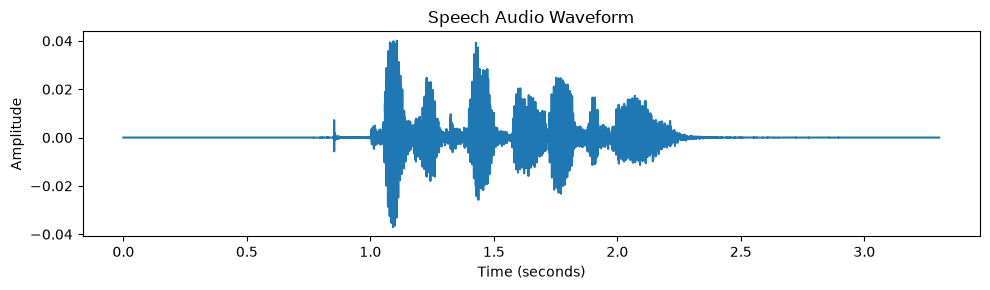

In [8]:

import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

sample_path = df.iloc[0]["file_path"]

# Read the WAV file without librosa
audio, sr = sf.read(sample_path)

# Convert stereo audio to mono if needed
if audio.ndim == 2:
    audio = audio.mean(axis=1)

print("Audio loaded successfully!")
print("Sample rate:", sr)
print("Duration:", round(len(audio) / sr, 2), "seconds")
print("Audio shape:", audio.shape)

plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(audio)) / sr, audio)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Speech Audio Waveform")
plt.tight_layout()
plt.show()


### 4. Extract MFCC features from one audio file

MFCC extraction successful!
MFCC shape: (40, 330)
Emotion: neutral


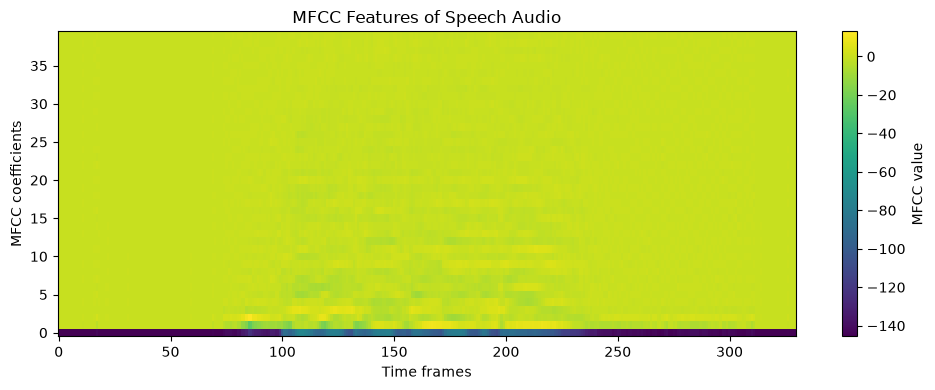

In [9]:

import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

def extract_mfcc_numpy(
    file_path,
    target_sr=16000,
    n_mfcc=40,
    n_fft=512,
    hop_length=160,
    n_mels=40,
    max_frames=330
):
    # 1. Read audio
    audio, sr = sf.read(file_path, dtype="float32")

    # Convert stereo audio to mono
    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    # 2. Resample if needed
    if sr != target_sr:
        duration = len(audio) / sr
        old_times = np.arange(len(audio)) / sr
        new_times = np.arange(int(duration * target_sr)) / target_sr
        audio = np.interp(
            new_times, old_times, audio
        ).astype(np.float32)
        sr = target_sr

    if len(audio) == 0:
        raise ValueError("Audio file is empty.")

    # 3. Pre-emphasis
    audio = np.append(
        audio[0],
        audio[1:] - 0.97 * audio[:-1]
    )

    # 4. Split audio into overlapping frames
    audio = np.pad(audio, (n_fft // 2, n_fft // 2))
    starts = np.arange(
        0, len(audio) - n_fft + 1, hop_length
    )

    frames = np.stack([
        audio[start:start + n_fft]
        for start in starts
    ])

    # 5. Apply Hamming window and FFT
    frames = frames * np.hamming(n_fft)
    spectrum = np.fft.rfft(frames, n=n_fft, axis=1)
    power = (np.abs(spectrum) ** 2) / n_fft

    # 6. Create Mel filter bank
    def hz_to_mel(hz):
        return 2595 * np.log10(1 + hz / 700)

    def mel_to_hz(mel):
        return 700 * (10 ** (mel / 2595) - 1)

    mel_points = np.linspace(
        hz_to_mel(0),
        hz_to_mel(sr / 2),
        n_mels + 2
    )
    mel_freqs = mel_to_hz(mel_points)
    fft_freqs = np.linspace(0, sr / 2, n_fft // 2 + 1)

    filters = np.zeros((n_mels, len(fft_freqs)))

    for m in range(n_mels):
        left, center, right = mel_freqs[m:m + 3]

        rising = (fft_freqs - left) / (center - left)
        falling = (right - fft_freqs) / (right - center)

        filters[m] = np.maximum(
            0, np.minimum(rising, falling)
        )

    # 7. Calculate log Mel energies
    mel_energy = power @ filters.T
    log_mel = np.log(np.maximum(mel_energy, 1e-10))

    # 8. Calculate MFCC using a cosine transform
    k = np.arange(n_mfcc)[:, None]
    n = np.arange(n_mels)[None, :]

    dct = np.cos(
        np.pi / n_mels * (n + 0.5) * k
    )
    dct[0, :] *= np.sqrt(1 / n_mels)
    dct[1:, :] *= np.sqrt(2 / n_mels)

    mfcc = dct @ log_mel.T

    # 9. Make every audio feature the same length
    if mfcc.shape[1] < max_frames:
        mfcc = np.pad(
            mfcc,
            ((0, 0), (0, max_frames - mfcc.shape[1]))
        )
    else:
        mfcc = mfcc[:, :max_frames]

    return mfcc.astype(np.float32)


# Test on one audio file
sample_path = df.iloc[0]["file_path"]
sample_mfcc = extract_mfcc_numpy(sample_path)

print("MFCC extraction successful!")
print("MFCC shape:", sample_mfcc.shape)
print("Emotion:", df.iloc[0]["emotion"])

plt.figure(figsize=(10, 4))
plt.imshow(
    sample_mfcc,
    aspect="auto",
    origin="lower",
    interpolation="nearest"
)
plt.xlabel("Time frames")
plt.ylabel("MFCC coefficients")
plt.title("MFCC Features of Speech Audio")
plt.colorbar(label="MFCC value")
plt.tight_layout()
plt.show()


### 5. Extract MFCC features from all audio files

In [10]:

from pathlib import Path
import numpy as np
import pandas as pd

# Create output folder
Path("results").mkdir(parents=True, exist_ok=True)

features = []
labels = []
successful_files = []
failed_files = []

# Process all audio files
total_files = len(df)

for i, row in enumerate(df.itertuples(index=False), start=1):
    try:
        mfcc = extract_mfcc_numpy(row.file_path)

        features.append(mfcc)
        labels.append(row.emotion)
        successful_files.append(row.filename)

    except Exception as e:
        failed_files.append({
            "filename": row.filename,
            "error": str(e)
        })

    # Display progress
    if i % 100 == 0 or i == total_files:
        print(f"Processed {i}/{total_files} audio files")

# Convert extracted features into a NumPy array
X = np.stack(features).astype(np.float32)
y = np.array(labels)

# Save features and labels
np.save("results/mfcc_features.npy", X)
np.save("results/emotion_labels.npy", y)

# Save the list of successfully processed files
pd.DataFrame({
    "filename": successful_files,
    "emotion": labels
}).to_csv("results/processed_audio_files.csv", index=False)

# Save errors if any files failed
if failed_files:
    pd.DataFrame(failed_files).to_csv(
        "results/failed_audio_files.csv",
        index=False
    )

print("\nMFCC extraction completed!")
print("Feature array shape:", X.shape)
print("Labels shape:", y.shape)
print("Successful files:", len(successful_files))
print("Failed files:", len(failed_files))
print("Features saved to: results/mfcc_features.npy")
print("Labels saved to: results/emotion_labels.npy")


Processed 100/1440 audio files
Processed 200/1440 audio files
Processed 300/1440 audio files
Processed 400/1440 audio files
Processed 500/1440 audio files
Processed 600/1440 audio files
Processed 700/1440 audio files
Processed 800/1440 audio files
Processed 900/1440 audio files
Processed 1000/1440 audio files
Processed 1100/1440 audio files
Processed 1200/1440 audio files
Processed 1300/1440 audio files
Processed 1400/1440 audio files
Processed 1440/1440 audio files

MFCC extraction completed!
Feature array shape: (1440, 40, 330)
Labels shape: (1440,)
Successful files: 1440
Failed files: 0
Features saved to: results/mfcc_features.npy
Labels saved to: results/emotion_labels.npy


### 6. Split the dataset into training and testing sets

In [11]:

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder

# Load the saved MFCC features and emotion labels
X = np.load("results/mfcc_features.npy")
y = np.load("results/emotion_labels.npy", allow_pickle=True)

# Actor IDs must remain aligned with the audio files
groups = df["actor"].to_numpy()

# Convert emotion names into numeric labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split by actor to reduce data leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y_encoded, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y_encoded[train_idx]
y_test = y_encoded[test_idx]

# Save the emotion class names for later predictions
np.save("results/emotion_classes.npy", label_encoder.classes_)

# Save the split data
np.savez_compressed(
    "results/train_test_data.npz",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    train_idx=train_idx,
    test_idx=test_idx
)

print("Dataset split completed successfully!")
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

print("\nEmotion classes:")
print(label_encoder.classes_)

print("\nTraining actors:", len(np.unique(groups[train_idx])))
print("Testing actors:", len(np.unique(groups[test_idx])))

# Confirm that no actors appear in both sets
train_actors = set(groups[train_idx])
test_actors = set(groups[test_idx])

print("Actor overlap:", train_actors.intersection(test_actors))


Dataset split completed successfully!
Training features: (1140, 40, 330)
Testing features: (300, 40, 330)
Training labels: (1140,)
Testing labels: (300,)

Emotion classes:
['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']

Training actors: 19
Testing actors: 5
Actor overlap: set()


### 7. Build and train your CNN model

In [12]:

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from pathlib import Path

# 1. Set up the device
device = torch.device("cpu")
print("Training device:", device)

# 2. Load the saved training and testing data
data = np.load("results/train_test_data.npz")

X_train = data["X_train"].astype(np.float32)
X_test = data["X_test"].astype(np.float32)
y_train = data["y_train"].astype(np.int64)
y_test = data["y_test"].astype(np.int64)

# 3. Normalize MFCC features using training data only
mean = X_train.mean(axis=(0, 2), keepdims=True)
std = X_train.std(axis=(0, 2), keepdims=True)

X_train = (X_train - mean) / (std + 1e-6)
X_test = (X_test - mean) / (std + 1e-6)

# Add the channel dimension required by CNN
X_train = X_train[:, np.newaxis, :, :]
X_test = X_test[:, np.newaxis, :, :]

# Convert NumPy arrays into PyTorch tensors
train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# 4. Define the CNN architecture
class EmotionCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((5, 10))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 5 * 10, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# 5. Initialize the model and training settings
torch.manual_seed(42)

model = EmotionCNN(num_classes=8).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("\nCNN model created successfully!")
print(model)

# 6. Train the CNN
epochs = 15

for epoch in range(epochs):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * inputs.size(0)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    avg_loss = total_loss / total
    train_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Loss: {avg_loss:.4f} "
        f"Training Accuracy: {train_accuracy:.2f}%"
    )

# 7. Save the trained model and normalization values
Path("models").mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "mean": mean,
        "std": std,
        "num_classes": 8
    },
    "models/emotion_cnn.pth"
)

print("\nTraining completed!")
print("Model saved to: models/emotion_cnn.pth")


Training device: cpu

CNN model created successfully!
EmotionCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): AdaptiveAvgPool2d(output_size=(5, 10))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3200, out_featur

### 8. Evaluate your trained CNN model

Test Accuracy: 43.67%

Classification Report:
              precision    recall  f1-score   support

       angry       0.74      0.57      0.65        40
        calm       0.89      0.40      0.55        40
     disgust       0.68      0.38      0.48        40
     fearful       0.41      0.45      0.43        40
       happy       0.33      0.57      0.42        40
     neutral       1.00      0.10      0.18        20
         sad       0.25      0.55      0.34        40
   surprised       0.48      0.30      0.37        40

    accuracy                           0.44       300
   macro avg       0.60      0.42      0.43       300
weighted avg       0.57      0.44      0.44       300



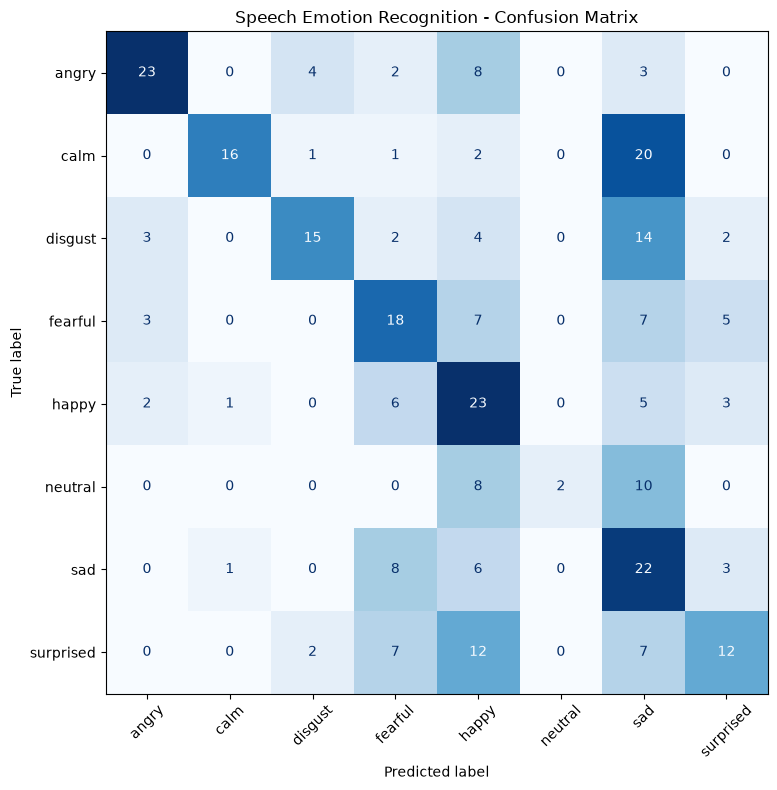


Evaluation completed!
Report saved: results/classification_report.txt
Confusion matrix saved: results/confusion_matrix.png


In [13]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load emotion class names
emotion_classes = np.load(
    "results/emotion_classes.npy",
    allow_pickle=True
).tolist()

# Evaluate the trained model
model.eval()
all_predictions = []
all_true_labels = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_true_labels.extend(targets.numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(
    all_true_labels,
    all_predictions
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# Generate classification report
report = classification_report(
    all_true_labels,
    all_predictions,
    labels=list(range(len(emotion_classes))),
    target_names=emotion_classes,
    zero_division=0
)

print("\nClassification Report:")
print(report)

# Save evaluation results
Path("results").mkdir(parents=True, exist_ok=True)

with open(
    "results/classification_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(f"Test Accuracy: {test_accuracy * 100:.2f}%\n\n")
    file.write(report)

# Create and save confusion matrix
cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=list(range(len(emotion_classes)))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=emotion_classes
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Speech Emotion Recognition - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "results/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nEvaluation completed!")
print("Report saved: results/classification_report.txt")
print("Confusion matrix saved: results/confusion_matrix.png")


### 9. Improve the CNN model

In [14]:

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score

# Load the original MFCC features and saved split
X_all = np.load("results/mfcc_features.npy").astype(np.float32)
y_all = np.load("results/emotion_labels.npy", allow_pickle=True)

saved = np.load("results/train_test_data.npz")
train_idx = saved["train_idx"]
test_idx = saved["test_idx"]

groups = df["actor"].to_numpy()

# Split training actors into training and validation actors
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=21
)

subtrain_pos, val_pos = next(
    splitter.split(
        X_all[train_idx],
        y_all[train_idx],
        groups=groups[train_idx]
    )
)

subtrain_idx = train_idx[subtrain_pos]
val_idx = train_idx[val_pos]

# Calculate normalization using training data only
mean = X_all[subtrain_idx].mean(
    axis=(0, 2), keepdims=True
)
std = X_all[subtrain_idx].std(
    axis=(0, 2), keepdims=True
) + 1e-6

def prepare_features(indices):
    values = (X_all[indices] - mean) / std
    values = values[:, np.newaxis, :, :]
    return torch.from_numpy(values.astype(np.float32))

X_subtrain = prepare_features(subtrain_idx)
X_val = prepare_features(val_idx)

# Encode labels using the existing saved class order
classes = np.load(
    "results/emotion_classes.npy",
    allow_pickle=True
)
class_to_id = {name: i for i, name in enumerate(classes)}

y_subtrain = torch.tensor(
    [class_to_id[v] for v in y_all[subtrain_idx]],
    dtype=torch.long
)
y_val = torch.tensor(
    [class_to_id[v] for v in y_all[val_idx]],
    dtype=torch.long
)

train_loader = DataLoader(
    TensorDataset(X_subtrain, y_subtrain),
    batch_size=32,
    shuffle=True
)
val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=64,
    shuffle=False
)

# A smaller CNN with stronger regularization
class ImprovedEmotionCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 48, 3, padding=1),
            nn.BatchNorm2d(48),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(48, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


torch.manual_seed(42)
model = ImprovedEmotionCNN(num_classes=len(classes))
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

best_val_loss = float("inf")
best_state = None
patience = 6
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        correct += (outputs.argmax(1) == targets).sum().item()
        total += targets.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            val_loss_sum += loss.item() * inputs.size(0)
            val_correct += (
                outputs.argmax(1) == targets
            ).sum().item()
            val_total += targets.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total
    scheduler.step(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{max_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc * 100:.2f}% | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc * 100:.2f}%"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping: validation loss did not improve.")
        break

# Restore the best validation model and save it
if best_state is None:
    raise RuntimeError("Training did not produce a valid model.")

model.load_state_dict(best_state)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "mean": mean,
        "std": std,
        "num_classes": len(classes)
    },
    "models/emotion_cnn.pth"
)

print("\nImproved model saved to models/emotion_cnn.pth")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Training actors: {len(np.unique(groups[subtrain_idx]))}")
print(f"Validation actors: {len(np.unique(groups[val_idx]))}")


Epoch 01/30 | Train loss: 2.0630 | Train acc: 14.89% | Val loss: 2.0067 | Val acc: 22.08%
Epoch 02/30 | Train loss: 2.0007 | Train acc: 19.22% | Val loss: 1.9586 | Val acc: 27.92%
Epoch 03/30 | Train loss: 1.9666 | Train acc: 22.00% | Val loss: 1.9424 | Val acc: 21.67%
Epoch 04/30 | Train loss: 1.9637 | Train acc: 21.22% | Val loss: 1.9086 | Val acc: 27.92%
Epoch 05/30 | Train loss: 1.9525 | Train acc: 24.22% | Val loss: 1.8848 | Val acc: 31.67%
Epoch 06/30 | Train loss: 1.9105 | Train acc: 27.89% | Val loss: 1.8523 | Val acc: 33.33%
Epoch 07/30 | Train loss: 1.9276 | Train acc: 24.22% | Val loss: 1.8376 | Val acc: 28.75%
Epoch 08/30 | Train loss: 1.9001 | Train acc: 26.67% | Val loss: 1.8320 | Val acc: 33.75%
Epoch 09/30 | Train loss: 1.8844 | Train acc: 28.00% | Val loss: 1.8536 | Val acc: 29.17%
Epoch 10/30 | Train loss: 1.8722 | Train acc: 27.78% | Val loss: 1.7959 | Val acc: 37.92%
Epoch 11/30 | Train loss: 1.8574 | Train acc: 32.00% | Val loss: 1.8994 | Val acc: 25.00%
Epoch 12/3

### 10. Evaluate the improved model

In [15]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# Load the improved model checkpoint
checkpoint = torch.load(
    "models/emotion_cnn.pth",
    map_location="cpu",
    weights_only=True
)

# Restore the correct model architecture
classes = np.load(
    "results/emotion_classes.npy",
    allow_pickle=True
).tolist()

model = ImprovedEmotionCNN(num_classes=len(classes))
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Load the original, untouched test samples
data = np.load("results/train_test_data.npz")
X_test_raw = np.load("results/mfcc_features.npy")[data["test_idx"]]
y_test = data["y_test"].astype(np.int64)

# Normalize using the improved model's training statistics
mean = checkpoint["mean"]
std = checkpoint["std"]

X_test_norm = (X_test_raw - mean) / (std + 1e-6)
X_test_norm = X_test_norm[:, np.newaxis, :, :].astype(np.float32)

X_test_tensor = torch.from_numpy(X_test_norm)

# Predict emotions
with torch.no_grad():
    outputs = model(X_test_tensor)
    predictions = outputs.argmax(dim=1).numpy()

# Calculate accuracy and report
accuracy = accuracy_score(y_test, predictions)

print(f"Improved Model Test Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

# Save the report
with open(
    "results/improved_classification_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(f"Test Accuracy: {accuracy * 100:.2f}%\n\n")
    file.write(classification_report(
        y_test,
        predictions,
        labels=list(range(len(classes))),
        target_names=classes,
        zero_division=0
    ))

# Plot confusion matrix
cm = confusion_matrix(
    y_test,
    predictions,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("Improved CNN - Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "results/improved_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSaved: results/improved_classification_report.txt")
print("Saved: results/improved_confusion_matrix.png")


UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray._reconstruct was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray._reconstruct])` or the `torch.serialization.safe_globals([numpy._core.multiarray._reconstruct])` context manager to allowlist this global if you trust this class/function.

Check the documentation of to

In [16]:
import torch
import numpy as np

checkpoint = torch.load(
    "models/emotion_cnn.pth",
    map_location="cpu",
    weights_only=False
)

print("Model checkpoint loaded successfully!")
print("Checkpoint keys:", checkpoint.keys())

Model checkpoint loaded successfully!
Checkpoint keys: dict_keys(['model_state_dict', 'mean', 'std', 'num_classes'])


Improved CNN Test Accuracy: 38.00%

Classification Report:
              precision    recall  f1-score   support

       angry       0.43      0.45      0.44        40
        calm       0.31      1.00      0.48        40
     disgust       0.60      0.23      0.33        40
     fearful       0.43      0.55      0.48        40
       happy       0.43      0.15      0.22        40
     neutral       0.00      0.00      0.00        20
         sad       0.24      0.23      0.23        40
   surprised       0.71      0.25      0.37        40

    accuracy                           0.38       300
   macro avg       0.40      0.36      0.32       300
weighted avg       0.42      0.38      0.34       300



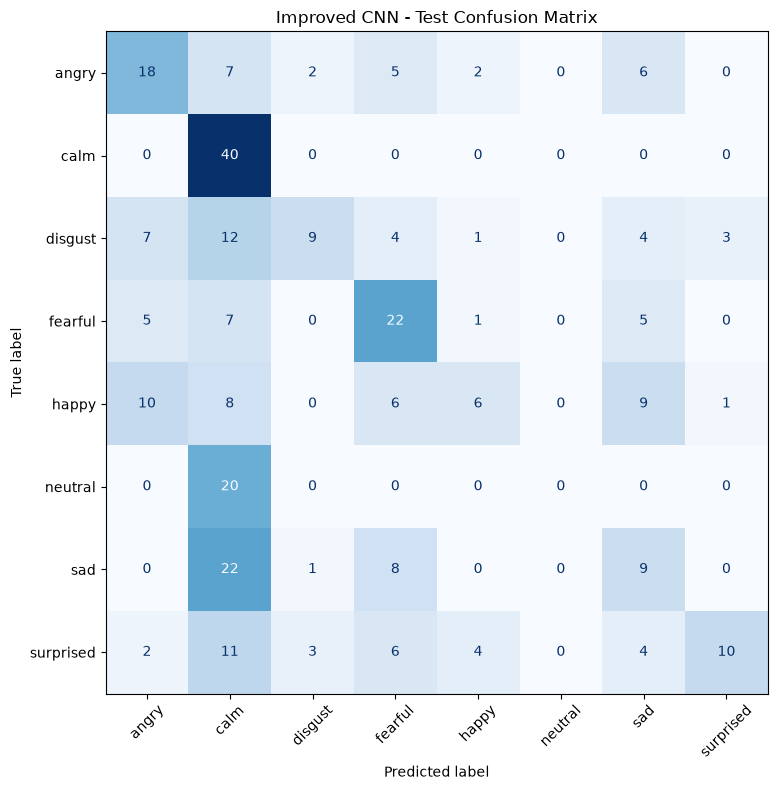


Evaluation files saved successfully:
results/improved_classification_report.txt
results/improved_confusion_matrix.png


In [17]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

# 1. Load emotion classes
classes = np.load(
    "results/emotion_classes.npy",
    allow_pickle=True
).tolist()

# 2. Load the improved CNN model
model = ImprovedEmotionCNN(num_classes=len(classes))
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# 3. Load test data
data = np.load("results/train_test_data.npz")

X_test_raw = np.load("results/mfcc_features.npy")[
    data["test_idx"]
]

y_test = data["y_test"].astype(np.int64)

# 4. Normalize test features using saved training statistics
mean = checkpoint["mean"]
std = checkpoint["std"]

X_test_norm = (X_test_raw - mean) / (std + 1e-6)
X_test_norm = X_test_norm[:, np.newaxis, :, :].astype(np.float32)

X_test_tensor = torch.from_numpy(X_test_norm)

# 5. Predict emotions
with torch.no_grad():
    outputs = model(X_test_tensor)
    predictions = outputs.argmax(dim=1).numpy()

# 6. Calculate accuracy
accuracy = accuracy_score(y_test, predictions)

print(f"Improved CNN Test Accuracy: {accuracy * 100:.2f}%")

# 7. Display classification report
report = classification_report(
    y_test,
    predictions,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
)

print("\nClassification Report:")
print(report)

# 8. Save classification report
with open(
    "results/improved_classification_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(f"Test Accuracy: {accuracy * 100:.2f}%\n\n")
    file.write(report)

# 9. Create and save confusion matrix
cm = confusion_matrix(
    y_test,
    predictions,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

plt.title("Improved CNN - Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "results/improved_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nEvaluation files saved successfully:")
print("results/improved_classification_report.txt")
print("results/improved_confusion_matrix.png")

In [18]:

from collections import Counter
import numpy as np

print("Actual test emotion counts:")
for i, emotion in enumerate(classes):
    count = int(np.sum(y_test == i))
    print(f"{emotion:12s}: {count}")

print("\nPredicted test emotion counts:")
pred_counts = Counter(predictions.tolist())

for i, emotion in enumerate(classes):
    count = pred_counts.get(i, 0)
    print(f"{emotion:12s}: {count}")

print("\nPrediction check completed.")


Actual test emotion counts:
angry       : 40
calm        : 40
disgust     : 40
fearful     : 40
happy       : 40
neutral     : 20
sad         : 40
surprised   : 40

Predicted test emotion counts:
angry       : 42
calm        : 127
disgust     : 15
fearful     : 51
happy       : 14
neutral     : 0
sad         : 37
surprised   : 14

Prediction check completed.


In [19]:

import numpy as np

# Load the extracted MFCC features
X_all = np.load("results/mfcc_features.npy")

# Load the training and testing split
data = np.load("results/train_test_data.npz")

X_train_raw = X_all[data["train_idx"]]
X_test_raw = X_all[data["test_idx"]]

print("TRAINING FEATURES")
print("Shape:", X_train_raw.shape)
print("Minimum:", np.min(X_train_raw))
print("Maximum:", np.max(X_train_raw))
print("Mean:", np.mean(X_train_raw))
print("Standard deviation:", np.std(X_train_raw))

print("\nTEST FEATURES")
print("Shape:", X_test_raw.shape)
print("Minimum:", np.min(X_test_raw))
print("Maximum:", np.max(X_test_raw))
print("Mean:", np.mean(X_test_raw))
print("Standard deviation:", np.std(X_test_raw))

print("\nFeature check completed.")


TRAINING FEATURES
Shape: (1140, 40, 330)
Minimum: -145.62827
Maximum: 17.394165
Mean: -3.120311
Standard deviation: 17.42587

TEST FEATURES
Shape: (300, 40, 330)
Minimum: -145.62827
Maximum: 16.447882
Mean: -3.0657318
Standard deviation: 17.453543

Feature check completed.


In [20]:

import numpy as np
from collections import Counter

data = np.load("results/train_test_data.npz")

y_train = data["y_train"].astype(int)
y_test = data["y_test"].astype(int)

classes = np.load(
    "results/emotion_classes.npy",
    allow_pickle=True
).tolist()

print("Training emotion distribution:")
counts = Counter(y_train.tolist())

for i, emotion in enumerate(classes):
    print(f"{emotion:12s}: {counts.get(i, 0)}")

print("\nTotal training samples:", len(y_train))
print("Total test samples:", len(y_test))


Training emotion distribution:
angry       : 152
calm        : 152
disgust     : 152
fearful     : 152
happy       : 152
neutral     : 76
sad         : 152
surprised   : 152

Total training samples: 1140
Total test samples: 300


###  Class-Weighted CNN Model for Speech Emotion Recognition

In [23]:

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import GroupShuffleSplit

# =====================================================
# 1. REPRODUCIBILITY
# =====================================================

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")
print("Device:", device)

# =====================================================
# 2. LOAD FEATURES, LABELS, AND CLASS NAMES
# =====================================================

X_all = np.load(
    "results/mfcc_features.npy"
).astype(np.float32)

emotion_names = np.load(
    "results/emotion_labels.npy",
    allow_pickle=True
).astype(str)

classes = np.load(
    "results/emotion_classes.npy",
    allow_pickle=True
).astype(str).tolist()

class_to_id = {
    emotion: index
    for index, emotion in enumerate(classes)
}

unknown_labels = sorted(set(emotion_names) - set(classes))
if unknown_labels:
    raise ValueError(f"Unknown emotion labels: {unknown_labels}")

y_all = np.array(
    [class_to_id[emotion] for emotion in emotion_names],
    dtype=np.int64
)

print("\nFeatures:", X_all.shape)
print("Labels:", y_all.shape)
print("Classes:", classes)

if len(X_all) != len(y_all):
    raise ValueError("Feature count and label count do not match.")

# =====================================================
# 3. LOAD THE EXISTING TRAIN/TEST SPLIT
# =====================================================

data = np.load("results/train_test_data.npz")

train_idx = data["train_idx"].astype(int)
test_idx = data["test_idx"].astype(int)

if np.intersect1d(train_idx, test_idx).size:
    raise ValueError("Training and test indices overlap.")

if max(train_idx.max(), test_idx.max()) >= len(X_all):
    raise ValueError("Split indices exceed the feature count.")

print("Training samples:", len(train_idx))
print("Test samples:", len(test_idx))

# =====================================================
# 4. LOAD AND VERIFY ACTOR IDS
# =====================================================

df = pd.read_csv("results/processed_audio_files.csv")

print("\nCSV columns:", df.columns.tolist())

if len(df) != len(X_all):
    raise ValueError(
        "CSV rows and feature rows do not match. "
        "Do not train until filenames are matched to features."
    )

if "actor" in df.columns:
    groups = pd.to_numeric(
        df["actor"], errors="raise"
    ).to_numpy(dtype=int)

else:
    # Recover actor ID from a RAVDESS filename.
    filename_col = next(
        (
            col for col in ["filename", "file_path"]
            if col in df.columns
        ),
        None
    )

    if filename_col is None:
        raise ValueError(
            "CSV needs an actor, filename, or file_path column."
        )

    filenames = (
        df[filename_col]
        .astype(str)
        .str.replace("\\", "/", regex=False)
        .str.split("/")
        .str[-1]
        .str.replace(".wav", "", regex=False)
    )

    parts = filenames.str.split("-")

    if not parts.map(len).eq(7).all():
        raise ValueError(
            "Some filenames are not standard 7-part RAVDESS filenames."
        )

    groups = parts.str[-1].astype(int).to_numpy()

# Basic consistency checks
if len(groups) != len(X_all):
    raise ValueError("Actor IDs and features do not match.")

if not np.isin(groups, np.arange(1, 25)).all():
    raise ValueError(
        "Unexpected RAVDESS actor IDs. Check the CSV filenames."
    )

print("Unique actors:", len(np.unique(groups)))

# =====================================================
# 5. CREATE ACTOR-INDEPENDENT VALIDATION SPLIT
# =====================================================

train_groups = groups[train_idx]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=21
)

subtrain_pos, val_pos = next(
    splitter.split(
        X_all[train_idx],
        y_all[train_idx],
        groups=train_groups
    )
)

subtrain_idx = train_idx[subtrain_pos]
val_idx = train_idx[val_pos]

subtrain_actors = set(groups[subtrain_idx])
val_actors = set(groups[val_idx])
test_actors = set(groups[test_idx])

assert subtrain_actors.isdisjoint(val_actors)
assert subtrain_actors.isdisjoint(test_actors)
assert val_actors.isdisjoint(test_actors)

print("\nSubtraining samples:", len(subtrain_idx))
print("Validation samples:", len(val_idx))
print("Test samples:", len(test_idx))
print("Subtraining actors:", len(subtrain_actors))
print("Validation actors:", len(val_actors))
print("Test actors:", len(test_actors))

# =====================================================
# 6. NORMALIZE USING SUBTRAINING DATA ONLY
# =====================================================

mean = X_all[subtrain_idx].mean(
    axis=(0, 2), keepdims=True
)

std = X_all[subtrain_idx].std(
    axis=(0, 2), keepdims=True
)

def prepare_features(indices):
    X = (X_all[indices] - mean) / (std + 1e-6)
    X = X[:, np.newaxis, :, :]
    return torch.from_numpy(X.astype(np.float32))

X_sub = prepare_features(subtrain_idx)
X_val = prepare_features(val_idx)

y_sub = torch.from_numpy(y_all[subtrain_idx])
y_val = torch.from_numpy(y_all[val_idx])

train_loader = DataLoader(
    TensorDataset(X_sub, y_sub),
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(X_val, y_val),
    batch_size=64,
    shuffle=False
)

# =====================================================
# 7. CALCULATE CLASS WEIGHTS
# =====================================================

num_classes = len(classes)

class_counts = np.bincount(
    y_all[subtrain_idx],
    minlength=num_classes
)

if np.any(class_counts == 0):
    raise ValueError(
        "A class has no subtraining examples. "
        "Use a different actor validation split."
    )

class_weights = len(subtrain_idx) / (
    num_classes * class_counts
)

weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("\nClass counts and weights:")
for name, count, weight in zip(
    classes, class_counts, class_weights
):
    print(f"{name:12s}: {count:3d} samples | weight {weight:.3f}")

# =====================================================
# 8. BUILD THE CNN
# =====================================================

# Ensure the ImprovedEmotionCNN class has been defined
# in a previously executed notebook cell.
if "ImprovedEmotionCNN" not in globals():
    raise NameError(
        "Run the notebook cell defining ImprovedEmotionCNN first."
    )

model = ImprovedEmotionCNN(
    num_classes=num_classes
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=weights_tensor
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

# =====================================================
# 9. TRAIN WITH EARLY STOPPING
# =====================================================

best_val_loss = float("inf")
best_state = None
patience = 6
epochs_without_improvement = 0
max_epochs = 30

for epoch in range(max_epochs):

    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * len(yb)
        train_correct += (logits.argmax(1) == yb).sum().item()
        train_total += len(yb)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            val_loss_sum += loss.item() * len(yb)
            val_correct += (logits.argmax(1) == yb).sum().item()
            val_total += len(yb)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    scheduler.step(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{max_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.2%}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# =====================================================
# 10. RESTORE AND SAVE BEST MODEL
# =====================================================

if best_state is None:
    raise RuntimeError("No valid model checkpoint was produced.")

model.load_state_dict(best_state)

os.makedirs("models", exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "mean": mean,
        "std": std,
        "num_classes": num_classes,
        "classes": classes
    },
    "models/emotion_cnn_weighted.pth"
)

print("\nWeighted CNN saved successfully.")
print("Location: models/emotion_cnn_weighted.pth")
print(f"Best validation loss: {best_val_loss:.4f}")
print("The test set was not used during training.")


Device: cpu

Features: (1440, 40, 330)
Labels: (1440,)
Classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
Training samples: 1140
Test samples: 300

CSV columns: ['filename', 'emotion']
Unique actors: 24

Subtraining samples: 900
Validation samples: 240
Test samples: 300
Subtraining actors: 15
Validation actors: 4
Test actors: 5

Class counts and weights:
angry       : 120 samples | weight 0.938
calm        : 120 samples | weight 0.938
disgust     : 120 samples | weight 0.938
fearful     : 120 samples | weight 0.938
happy       : 120 samples | weight 0.938
neutral     :  60 samples | weight 1.875
sad         : 120 samples | weight 0.938
surprised   : 120 samples | weight 0.938
Epoch 01/30 | Train loss: 2.0838 | Train acc: 14.78% | Val loss: 2.0365 | Val acc: 21.67%
Epoch 02/30 | Train loss: 2.0194 | Train acc: 19.22% | Val loss: 2.0071 | Val acc: 19.17%
Epoch 03/30 | Train loss: 1.9815 | Train acc: 21.67% | Val loss: 1.9579 | Val acc: 24.58%
Epoch 0

### Evaluate weighted CNN

Device: cpu
Test features: (300, 40, 330)
Test labels: (300,)
Emotion classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']

WEIGHTED CNN TEST RESULTS
Test Accuracy: 42.33%
Correct Predictions: 127 / 300

Classification Report:

              precision    recall  f1-score   support

       angry     0.3607    0.5500    0.4356        40
        calm     0.4744    0.9250    0.6271        40
     disgust     0.4815    0.3250    0.3881        40
     fearful     0.4545    0.2500    0.3226        40
       happy     0.5000    0.1250    0.2000        40
     neutral     0.2703    0.5000    0.3509        20
         sad     0.3077    0.2000    0.2424        40
   surprised     0.5641    0.5500    0.5570        40

    accuracy                         0.4233       300
   macro avg     0.4266    0.4281    0.3905       300
weighted avg     0.4371    0.4233    0.3931       300



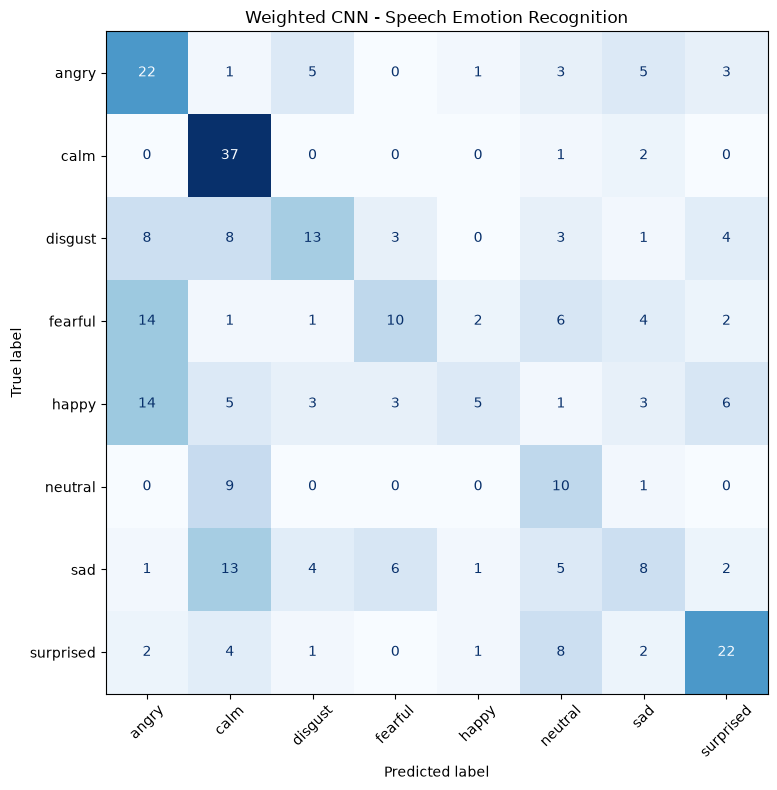


Evaluation completed successfully!
Saved files:
- results/weighted_classification_report.txt
- results/weighted_confusion_matrix.png
- results/weighted_test_predictions.csv


In [24]:

# ============================================================
# Evaluate Class-Weighted CNN for Speech Emotion Recognition
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Set device
device = torch.device("cpu")
print("Device:", device)

# 2. Load features, labels, and class names
X_all = np.load("results/mfcc_features.npy").astype(np.float32)

emotion_names = np.load(
    "results/emotion_labels.npy", allow_pickle=True
).astype(str)

classes = np.load(
    "results/emotion_classes.npy", allow_pickle=True
).astype(str).tolist()

class_to_id = {name: i for i, name in enumerate(classes)}
y_all = np.array(
    [class_to_id[name] for name in emotion_names],
    dtype=np.int64
)

# 3. Load the original, untouched test indices
split = np.load("results/train_test_data.npz")

if "test_idx" not in split.files:
    raise KeyError(
        "test_idx is missing from train_test_data.npz. "
        "Use the original test split created for this project."
    )

test_idx = split["test_idx"].astype(np.int64)

X_test = X_all[test_idx]
y_test = y_all[test_idx]

print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)
print("Emotion classes:", classes)

assert len(X_test) == len(y_test), "Test feature/label count mismatch."
assert len(test_idx) == 300, (
    "Expected 300 test samples. Check that you loaded the original split."
)

# 4. Define the same CNN architecture used during training
class ImprovedEmotionCNN(nn.Module):
    def __init__(self, num_classes=8):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 48, kernel_size=3, padding=1),
            nn.BatchNorm2d(48),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(48, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

# 5. Load the saved weighted model and normalization statistics
checkpoint_path = "models/emotion_cnn_weighted.pth"

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(
        f"Model checkpoint not found: {checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
    raise ValueError(
        "This checkpoint does not contain model_state_dict. "
        "Check that you are loading emotion_cnn_weighted.pth."
    )

if "mean" not in checkpoint or "std" not in checkpoint:
    raise KeyError(
        "Normalization statistics are missing from the checkpoint. "
        "Use the mean and std saved during weighted model training."
    )

# Confirm that the saved class order matches the current class order
saved_classes = [str(c) for c in checkpoint["classes"]]
if saved_classes != classes:
    raise ValueError(
        f"Class order mismatch!\nSaved: {saved_classes}\nCurrent: {classes}"
    )

model = ImprovedEmotionCNN(num_classes=len(classes)).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

mean = np.asarray(checkpoint["mean"], dtype=np.float32)
std = np.asarray(checkpoint["std"], dtype=np.float32)

# 6. Apply the same normalization used during training
X_test_normalized = (X_test - mean) / (std + 1e-6)

# Add channel dimension: (samples, 1, 40, 330)
X_test_tensor = torch.from_numpy(
    X_test_normalized[:, np.newaxis, :, :]
).float().to(device)

y_test_tensor = torch.from_numpy(y_test).long()

# 7. Make predictions without updating the model
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 32):
        batch = X_test_tensor[start:start + 32]
        outputs = model(batch)
        predictions = torch.argmax(outputs, dim=1)
        all_predictions.extend(predictions.cpu().numpy())

y_pred = np.asarray(all_predictions, dtype=np.int64)

# 8. Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\n" + "=" * 55)
print("WEIGHTED CNN TEST RESULTS")
print("=" * 55)
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Correct Predictions: {(y_test == y_pred).sum()} / {len(y_test)}")

# 9. Display the classification report
report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=4,
    zero_division=0
)

print("\nClassification Report:\n")
print(report)

os.makedirs("results", exist_ok=True)

with open(
    "results/weighted_classification_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("Class-Weighted CNN Evaluation\n")
    file.write(f"Test Accuracy: {accuracy * 100:.2f}%\n\n")
    file.write(report)

# 10. Plot and save the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(classes))
)

fig, ax = plt.subplots(figsize=(10, 8))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("Weighted CNN - Speech Emotion Recognition")
plt.tight_layout()
plt.savefig(
    "results/weighted_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 11. Save actual and predicted emotions for each test sample
results_df = pd.DataFrame({
    "actual_emotion": [classes[i] for i in y_test],
    "predicted_emotion": [classes[i] for i in y_pred],
    "correct": y_test == y_pred
})

results_df.to_csv(
    "results/weighted_test_predictions.csv",
    index=False
)

print("\nEvaluation completed successfully!")
print("Saved files:")
print("- results/weighted_classification_report.txt")
print("- results/weighted_confusion_matrix.png")
print("- results/weighted_test_predictions.csv")


### #Prepare the data and create a validation split

In [25]:

# ============================================================
# STEP 1: Prepare Data for CNN-LSTM Speech Emotion Recognition
# ============================================================

import os
import re
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# 1. Load existing MFCC features and emotion labels
X_all = np.load("results/mfcc_features.npy").astype(np.float32)

emotion_names = np.load(
    "results/emotion_labels.npy",
    allow_pickle=True
).astype(str)

classes = np.load(
    "results/emotion_classes.npy",
    allow_pickle=True
).astype(str).tolist()

class_to_id = {name: i for i, name in enumerate(classes)}

y_all = np.array(
    [class_to_id[name] for name in emotion_names],
    dtype=np.int64
)

# 2. Load the original actor-independent train/test split
split = np.load("results/train_test_data.npz")

required_keys = {"train_idx", "test_idx"}
if not required_keys.issubset(split.files):
    raise KeyError(
        "The saved split must contain train_idx and test_idx. "
        f"Available keys: {split.files}"
    )

train_idx = split["train_idx"].astype(np.int64)
test_idx = split["test_idx"].astype(np.int64)

# 3. Load the audio file list
csv_path = "results/processed_audio_files.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(f"CSV file not found: {csv_path}")

df = pd.read_csv(csv_path)

if not {"filename", "emotion"}.issubset(df.columns):
    raise ValueError(
        "CSV must contain filename and emotion columns."
    )

# 4. Verify that CSV rows match the feature/label order
if len(df) != len(X_all) or len(df) != len(y_all):
    raise ValueError(
        "CSV, features, and labels have different row counts."
    )

csv_emotions = df["emotion"].astype(str).str.lower().to_numpy()
saved_emotions = np.char.lower(emotion_names)

if not np.array_equal(csv_emotions, saved_emotions):
    raise ValueError(
        "CSV emotion order does not match saved label order. "
        "Stop here so we can verify the file-to-feature alignment."
    )

# 5. Extract actor IDs from RAVDESS filenames or file paths
def get_actor_id(filename):
    text = str(filename)

    # First, check whether the path contains Actor_01, Actor_02, etc.
    match = re.search(r"Actor[_-]?(\d{2})", text, flags=re.IGNORECASE)

    if match:
        return int(match.group(1))

    # Otherwise, use the final number in the RAVDESS filename.
    # Example: 03-01-05-01-02-01-12.wav -> actor 12
    basename = os.path.basename(text)
    stem = os.path.splitext(basename)[0]
    parts = stem.split("-")

    if len(parts) == 7 and parts[-1].isdigit():
        return int(parts[-1])

    raise ValueError(
        f"Could not identify actor ID from filename: {filename}"
    )

actors = np.array(
    [get_actor_id(name) for name in df["filename"]],
    dtype=np.int64
)

# 6. Validate the original split
if (
    len(np.unique(train_idx)) != len(train_idx)
    or len(np.unique(test_idx)) != len(test_idx)
):
    raise ValueError("Duplicate indices found in the saved split.")

if (
    np.intersect1d(train_idx, test_idx).size > 0
    or np.any(train_idx < 0)
    or np.any(test_idx < 0)
    or np.any(train_idx >= len(X_all))
    or np.any(test_idx >= len(X_all))
):
    raise ValueError("The saved train/test indices are invalid.")

train_actors = set(actors[train_idx])
test_actors = set(actors[test_idx])

if train_actors.intersection(test_actors):
    raise ValueError(
        "Actor leakage detected in the original split. "
        "Do not train until the split is checked."
    )

# 7. Create an actor-independent validation split
# Validation actors come only from the original training set.
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=21
)

subtrain_local, val_local = next(
    gss.split(
        X_all[train_idx],
        y_all[train_idx],
        groups=actors[train_idx]
    )
)

subtrain_idx = train_idx[subtrain_local]
val_idx = train_idx[val_local]

subtrain_actors = set(actors[subtrain_idx])
val_actors = set(actors[val_idx])

# 8. Print summary
print("=" * 55)
print("CNN-LSTM DATA PREPARATION")
print("=" * 55)

print("Features shape:", X_all.shape)
print("Labels shape:", y_all.shape)
print("Classes:", classes)
print("Total actors:", len(np.unique(actors)))

print("\nOriginal training samples:", len(train_idx))
print("Subtraining samples:", len(subtrain_idx))
print("Validation samples:", len(val_idx))
print("Original test samples:", len(test_idx))

print("\nSubtraining actors:", sorted(subtrain_actors))
print("Validation actors:", sorted(val_actors))
print("Test actors:", sorted(test_actors))

assert not subtrain_actors.intersection(val_actors)
assert not subtrain_actors.intersection(test_actors)
assert not val_actors.intersection(test_actors)

print("\nSUCCESS: Actor-independent splits verified!")
print("The original test set remains untouched.")


CNN-LSTM DATA PREPARATION
Features shape: (1440, 40, 330)
Labels shape: (1440,)
Classes: ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
Total actors: 24

Original training samples: 1140
Subtraining samples: 900
Validation samples: 240
Original test samples: 300

Subtraining actors: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(11), np.int64(13), np.int64(15), np.int64(18), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
Validation actors: [np.int64(10), np.int64(14), np.int64(16), np.int64(24)]
Test actors: [np.int64(1), np.int64(9), np.int64(12), np.int64(17), np.int64(19)]

SUCCESS: Actor-independent splits verified!
The original test set remains untouched.


### #Build the CNN-LSTM architecture

In [26]:

# ============================================================
# STEP 2: Build the CNN-LSTM Model
# Speech Emotion Recognition using MFCC Features
# ============================================================

import torch
import torch.nn as nn
import numpy as np

# Use CPU, as in your previous experiments
device = torch.device("cpu")

# Make experiments more reproducible
torch.manual_seed(42)
np.random.seed(42)

# 1. Define the CNN-LSTM architecture
class CNNLSTMEmotionModel(nn.Module):

    def __init__(self, num_classes=8, hidden_size=64):
        super().__init__()

        # CNN extracts useful patterns from MFCC features
        self.cnn = nn.Sequential(
            nn.Conv2d(
                in_channels=1,
                out_channels=16,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=16,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        # CNN output: (batch, 64, 10, 82)
        # Average over the MFCC-frequency dimension.
        # Result: (batch, 82, 64), where 82 represents time steps.
        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        # Classify the final temporal representation
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # Expected input: (batch, 1, 40, 330)
        x = self.cnn(x)

        # Average over frequency; preserve time
        x = x.mean(dim=2)

        # Convert to (batch, time, channels) for LSTM
        x = x.transpose(1, 2)

        # LSTM learns temporal patterns
        lstm_output, _ = self.lstm(x)

        # Use the final time step
        final_features = lstm_output[:, -1, :]

        # Return eight emotion-class scores
        return self.classifier(final_features)


# 2. Create the model
model = CNNLSTMEmotionModel(
    num_classes=len(classes),
    hidden_size=64
).to(device)

# 3. Test the architecture using one sample
dummy_input = torch.randn(2, 1, 40, 330).to(device)

model.eval()
with torch.no_grad():
    dummy_output = model(dummy_input)

print("=" * 50)
print("CNN-LSTM MODEL CREATED SUCCESSFULLY")
print("=" * 50)
print("Device:", device)
print("Input shape:", tuple(dummy_input.shape))
print("Output shape:", tuple(dummy_output.shape))
print("Number of emotion classes:", len(classes))
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

assert dummy_output.shape == (2, len(classes))

print("\nModel architecture check passed!")
print("Next: prepare normalized tensors for training.")


CNN-LSTM MODEL CREATED SUCCESSFULLY
Device: cpu
Input shape: (2, 1, 40, 330)
Output shape: (2, 8)
Number of emotion classes: 8
Trainable parameters: 98856

Model architecture check passed!
Next: prepare normalized tensors for training.


### #Normalize data and create DataLoaders

In [27]:

# ============================================================
# STEP 3: Normalize Data and Prepare DataLoaders
# ============================================================

import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Use CPU
device = torch.device("cpu")

# 1. Select features and labels using the indices from Step 1
X_subtrain = X_all[subtrain_idx]
y_subtrain = y_all[subtrain_idx]

X_val = X_all[val_idx]
y_val = y_all[val_idx]

X_test = X_all[test_idx]
y_test = y_all[test_idx]

print("Original shapes:")
print("Subtraining:", X_subtrain.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# 2. Calculate normalization statistics using subtraining data only
# Each MFCC coefficient is normalized across samples and time frames.
feature_mean = X_subtrain.mean(
    axis=(0, 2),
    keepdims=True
)

feature_std = X_subtrain.std(
    axis=(0, 2),
    keepdims=True
)

feature_std = np.maximum(feature_std, 1e-6)

# 3. Normalize all splits using the same subtraining statistics
X_subtrain_norm = (X_subtrain - feature_mean) / feature_std
X_val_norm = (X_val - feature_mean) / feature_std
X_test_norm = (X_test - feature_mean) / feature_std

# 4. Add the channel dimension for the CNN
# Shape changes from (samples, 40, 330) to (samples, 1, 40, 330)
X_subtrain_norm = X_subtrain_norm[:, np.newaxis, :, :]
X_val_norm = X_val_norm[:, np.newaxis, :, :]
X_test_norm = X_test_norm[:, np.newaxis, :, :]

# 5. Convert arrays to PyTorch tensors
X_subtrain_tensor = torch.from_numpy(
    X_subtrain_norm.astype(np.float32)
)
y_subtrain_tensor = torch.from_numpy(
    y_subtrain.astype(np.int64)
)

X_val_tensor = torch.from_numpy(
    X_val_norm.astype(np.float32)
)
y_val_tensor = torch.from_numpy(
    y_val.astype(np.int64)
)

X_test_tensor = torch.from_numpy(
    X_test_norm.astype(np.float32)
)
y_test_tensor = torch.from_numpy(
    y_test.astype(np.int64)
)

# 6. Create datasets
train_dataset = TensorDataset(
    X_subtrain_tensor,
    y_subtrain_tensor
)

val_dataset = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

# 7. Create DataLoaders
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# 8. Display results
print("\n" + "=" * 50)
print("DATA PREPARATION COMPLETED")
print("=" * 50)

print("Training tensor:", tuple(X_subtrain_tensor.shape))
print("Validation tensor:", tuple(X_val_tensor.shape))
print("Test tensor:", tuple(X_test_tensor.shape))

print("\nTraining batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("\nTraining feature mean:", round(float(X_subtrain_norm.mean()), 4))
print("Training feature std:", round(float(X_subtrain_norm.std()), 4))

# Verify that the tensors are valid
assert X_subtrain_tensor.shape == (900, 1, 40, 330)
assert X_val_tensor.shape == (240, 1, 40, 330)
assert X_test_tensor.shape == (300, 1, 40, 330)

assert torch.isfinite(X_subtrain_tensor).all()
assert torch.isfinite(X_val_tensor).all()
assert torch.isfinite(X_test_tensor).all()

print("\nSUCCESS: All tensors are ready for CNN-LSTM training!")


Original shapes:
Subtraining: (900, 40, 330)
Validation: (240, 40, 330)
Test: (300, 40, 330)

DATA PREPARATION COMPLETED
Training tensor: (900, 1, 40, 330)
Validation tensor: (240, 1, 40, 330)
Test tensor: (300, 1, 40, 330)

Training batches: 29
Validation batches: 8
Test batches: 10

Training feature mean: 0.0
Training feature std: 1.0

SUCCESS: All tensors are ready for CNN-LSTM training!


### #Train the CNN-LSTM model

In [28]:

# ============================================================
# STEP 4: Train CNN-LSTM for Speech Emotion Recognition
# ============================================================

import os
import copy
import numpy as np
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight

# 1. Reproducibility and device
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")
model = model.to(device)

# 2. Calculate class weights from subtraining labels only
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=y_subtrain
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Emotion class weights:")
for emotion, weight in zip(classes, class_weights):
    print(f"{emotion:12s}: {weight:.3f}")

# 3. Loss function and optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

# 4. Training settings
num_epochs = 40
early_stopping_patience = 8

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

best_model_state = copy.deepcopy(model.state_dict())
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)

# 5. Training loop
for epoch in range(num_epochs):

    # ---------------- Training ----------------
    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, targets)

        loss.backward()

        # Helps prevent exploding gradients in recurrent networks
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss_sum += loss.item() * inputs.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == targets).sum().item()
        train_total += targets.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # ---------------- Validation ----------------
    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            val_loss_sum += loss.item() * inputs.size(0)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == targets).sum().item()
            val_total += targets.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    # Record metrics
    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    # Adjust learning rate using validation loss
    old_lr = optimizer.param_groups[0]["lr"]
    scheduler.step(val_loss)
    new_lr = optimizer.param_groups[0]["lr"]

    # Keep the best validation-loss checkpoint in memory
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch [{epoch + 1:02d}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy * 100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy * 100:.2f}% | "
        f"LR: {new_lr:.6f}"
    )

    if new_lr < old_lr:
        print("  Learning rate reduced.")

    if epochs_without_improvement >= early_stopping_patience:
        print("\nEarly stopping: validation loss did not improve.")
        break

# 6. Restore the best validation checkpoint
model.load_state_dict(best_model_state)
model.eval()

print("\n" + "=" * 55)
print("CNN-LSTM TRAINING COMPLETED")
print("=" * 55)
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(
    f"Validation accuracy at best epoch: "
    f"{history['val_accuracy'][best_epoch - 1] * 100:.2f}%"
)

# 7. Save the model and preprocessing information
checkpoint = {
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "mean": feature_mean.astype(np.float32),
    "std": feature_std.astype(np.float32),
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "architecture": "CNNLSTMEmotionModel"
}

model_path = "models/emotion_cnn_lstm.pth"
torch.save(checkpoint, model_path)

# Save training history
import pandas as pd

history_df = pd.DataFrame(history)
history_df.to_csv(
    "results/cnn_lstm_training_history.csv",
    index_label="epoch"
)

print("\nModel saved to:", model_path)
print("Training history saved to: results/cnn_lstm_training_history.csv")


Emotion class weights:
angry       : 0.938
calm        : 0.938
disgust     : 0.938
fearful     : 0.938
happy       : 0.938
neutral     : 1.875
sad         : 0.938
surprised   : 0.938
Epoch [01/40] Train Loss: 2.0802 | Train Acc: 12.33% | Val Loss: 2.0718 | Val Acc: 12.08% | LR: 0.000500
Epoch [02/40] Train Loss: 2.0604 | Train Acc: 13.78% | Val Loss: 2.0323 | Val Acc: 15.83% | LR: 0.000500
Epoch [03/40] Train Loss: 2.0360 | Train Acc: 14.44% | Val Loss: 1.9775 | Val Acc: 17.50% | LR: 0.000500
Epoch [04/40] Train Loss: 2.0107 | Train Acc: 15.22% | Val Loss: 1.9542 | Val Acc: 17.50% | LR: 0.000500
Epoch [05/40] Train Loss: 1.9918 | Train Acc: 16.56% | Val Loss: 1.9250 | Val Acc: 15.42% | LR: 0.000500
Epoch [06/40] Train Loss: 1.9802 | Train Acc: 17.11% | Val Loss: 1.9313 | Val Acc: 22.50% | LR: 0.000500
Epoch [07/40] Train Loss: 1.9729 | Train Acc: 19.89% | Val Loss: 1.9023 | Val Acc: 22.92% | LR: 0.000500
Epoch [08/40] Train Loss: 1.9415 | Train Acc: 22.33% | Val Loss: 1.9697 | Val Acc:

### #Evaluate the CNN-LSTM model

CNN-LSTM TEST RESULTS
Test Accuracy: 36.00%
Correct Predictions: 108 / 300

Classification Report:

              precision    recall  f1-score   support

       angry     0.2857    0.2000    0.2353        40
        calm     0.4571    0.4000    0.4267        40
     disgust     0.4878    0.5000    0.4938        40
     fearful     0.3750    0.3750    0.3750        40
       happy     0.4231    0.2750    0.3333        40
     neutral     0.2353    1.0000    0.3810        20
         sad     0.0000    0.0000    0.0000        40
   surprised     0.4186    0.4500    0.4337        40

    accuracy                         0.3600       300
   macro avg     0.3353    0.4000    0.3349       300
weighted avg     0.3420    0.3600    0.3318       300



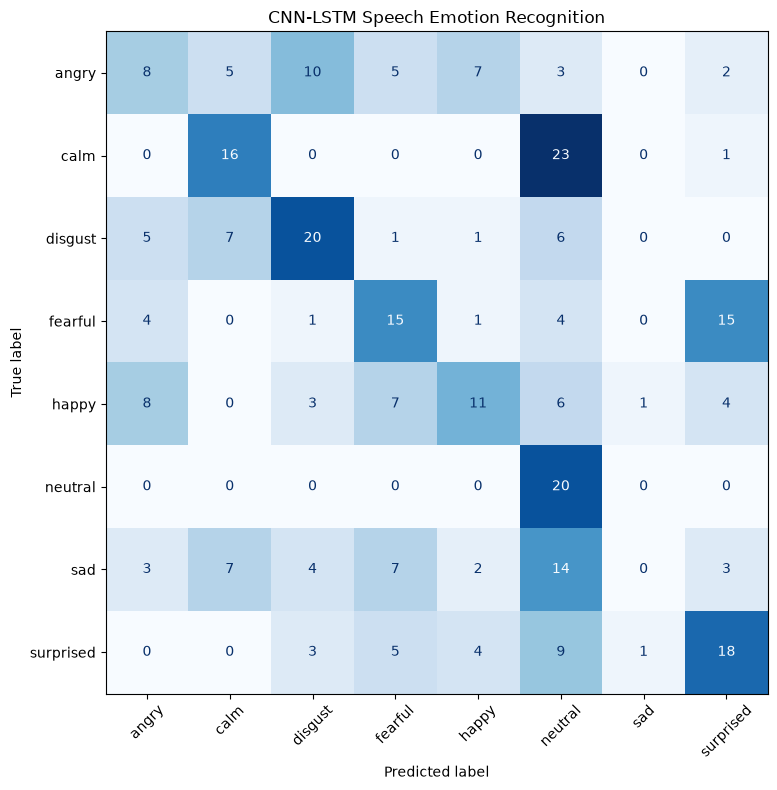


Evaluation completed successfully!
Saved:
- results/cnn_lstm_classification_report.txt
- results/cnn_lstm_confusion_matrix.png
- results/cnn_lstm_test_predictions.csv


In [30]:

# ============================================================
# STEP 5: Evaluate CNN-LSTM on the Original Test Set
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

device = torch.device("cpu")
model_path = "models/emotion_cnn_lstm.pth"

# 1. Load the saved checkpoint
if not os.path.exists(model_path):
    raise FileNotFoundError(f"Model not found: {model_path}")

checkpoint = torch.load(
    model_path,
    map_location=device,
    weights_only=False
)

# 2. Verify class order
saved_classes = [str(c) for c in checkpoint["classes"]]

if saved_classes != classes:
    raise ValueError(
        f"Class mismatch!\nSaved: {saved_classes}\nCurrent: {classes}"
    )

# 3. Recreate the same architecture
model = CNNLSTMEmotionModel(
    num_classes=len(classes),
    hidden_size=64
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# 4. Use the same training-only normalization statistics
mean = np.asarray(checkpoint["mean"], dtype=np.float32)
std = np.asarray(checkpoint["std"], dtype=np.float32)

X_test_raw = X_all[test_idx].astype(np.float32)
y_test_eval = y_all[test_idx].astype(np.int64)

X_test_norm = (X_test_raw - mean) / np.maximum(std, 1e-6)
X_test_norm = X_test_norm[:, np.newaxis, :, :]

X_test_eval_tensor = torch.from_numpy(
    X_test_norm.astype(np.float32)
)

# 5. Predict the test emotions
predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_eval_tensor), 32):
        batch = X_test_eval_tensor[start:start + 32].to(device)
        outputs = model(batch)
        predicted_ids = outputs.argmax(dim=1)
        predictions.extend(predicted_ids.cpu().numpy())

y_pred = np.asarray(predictions, dtype=np.int64)

# 6. Calculate test accuracy
accuracy = accuracy_score(y_test_eval, y_pred)

print("=" * 55)
print("CNN-LSTM TEST RESULTS")
print("=" * 55)
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(
    f"Correct Predictions: "
    f"{np.sum(y_test_eval == y_pred)} / {len(y_test_eval)}"
)

# 7. Classification report
report = classification_report(
    y_test_eval,
    y_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    digits=4,
    zero_division=0
)

print("\nClassification Report:\n")
print(report)

os.makedirs("results", exist_ok=True)

with open(
    "results/cnn_lstm_classification_report.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write("CNN-LSTM Speech Emotion Recognition\n")
    f.write(f"Test Accuracy: {accuracy * 100:.2f}%\n\n")
    f.write(report)

# 8. Confusion matrix
cm = confusion_matrix(
    y_test_eval,
    y_pred,
    labels=np.arange(len(classes))
)

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title("CNN-LSTM Speech Emotion Recognition")
plt.tight_layout()

plt.savefig(
    "results/cnn_lstm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 9. Save individual predictions
prediction_df = pd.DataFrame({
    "actual_emotion": [classes[i] for i in y_test_eval],
    "predicted_emotion": [classes[i] for i in y_pred],
    "correct": y_test_eval == y_pred
})

prediction_df.to_csv(
    "results/cnn_lstm_test_predictions.csv",
    index=False
)

print("\nEvaluation completed successfully!")
print("Saved:")
print("- results/cnn_lstm_classification_report.txt")
print("- results/cnn_lstm_confusion_matrix.png")
print("- results/cnn_lstm_test_predictions.csv")


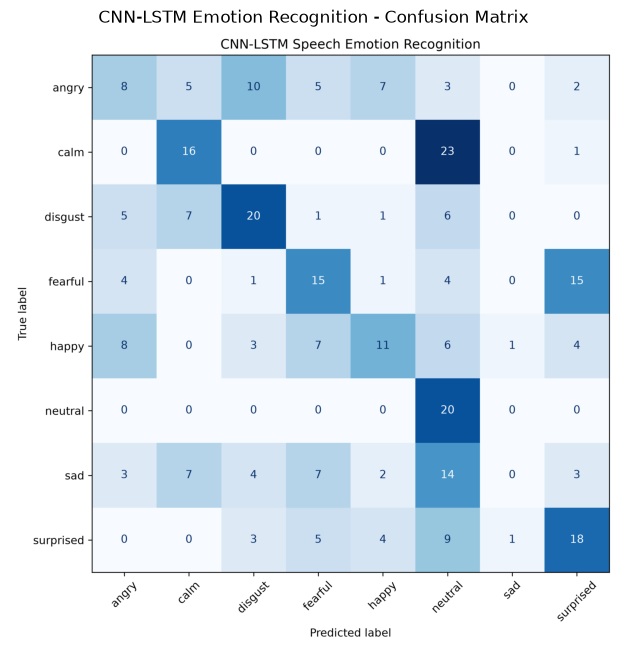

In [31]:
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# Load the saved CNN-LSTM confusion matrix
image = Image.open("results/cnn_lstm_confusion_matrix.png")

# Display the image
plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis("off")
plt.title("CNN-LSTM Emotion Recognition - Confusion Matrix")
plt.show()

In [32]:
import pandas as pd

# Load the saved CNN-LSTM test predictions
predictions = pd.read_csv(
    "results/cnn_lstm_test_predictions.csv"
)

# Display the column names first
print("Columns in prediction file:")
print(predictions.columns.tolist())

# Preview the first five rows
display(predictions.head())

Columns in prediction file:
['actual_emotion', 'predicted_emotion', 'correct']


,actual_emotion,predicted_emotion,correct
0,neutral,neutral,True
1,neutral,neutral,True
2,neutral,neutral,True
3,neutral,neutral,True
4,calm,neutral,False


### #Analyze misclassified emotions

In [33]:

import pandas as pd

# Load saved test predictions
predictions = pd.read_csv(
    "results/cnn_lstm_test_predictions.csv"
)

# Show the number of correct and incorrect predictions
print("Overall Prediction Summary")
print("=" * 40)
print(predictions["correct"].value_counts())

# Calculate correct predictions for each actual emotion
emotion_summary = predictions.groupby("actual_emotion").agg(
    total_samples=("correct", "count"),
    correct_predictions=("correct", "sum")
)

emotion_summary["incorrect_predictions"] = (
    emotion_summary["total_samples"]
    - emotion_summary["correct_predictions"]
)

emotion_summary["recall_percent"] = (
    emotion_summary["correct_predictions"]
    / emotion_summary["total_samples"] * 100
).round(2)

print("\nPerformance for Each Emotion")
display(emotion_summary)

# Show the most common types of mistakes
errors = predictions[predictions["correct"] == False]

error_summary = errors.groupby(
    ["actual_emotion", "predicted_emotion"]
).size().reset_index(name="count")

error_summary = error_summary.sort_values(
    "count", ascending=False
)

print("\nTop 10 Misclassification Patterns")
display(error_summary.head(10))


Overall Prediction Summary
correct
False    192
True     108
Name: count, dtype: int64

Performance for Each Emotion


,total_samples,correct_predictions,incorrect_predictions,recall_percent
actual_emotion,,,,
angry,40,8,32,20.0
calm,40,16,24,40.0
disgust,40,20,20,50.0
fearful,40,15,25,37.5
happy,40,11,29,27.5
neutral,20,20,0,100.0
sad,40,0,40,0.0
surprised,40,18,22,45.0



Top 10 Misclassification Patterns


,actual_emotion,predicted_emotion,count
6,calm,neutral,23
17,fearful,surprised,15
29,sad,neutral,14
1,angry,disgust,10
34,surprised,neutral,9
18,happy,angry,8
3,angry,happy,7
20,happy,fearful,7
27,sad,fearful,7
9,disgust,calm,7


In [34]:

def forward(self, x):
    x = self.cnn(x)

    # Convert CNN features into a time sequence
    x = x.mean(dim=2)
    x = x.transpose(1, 2)

    # Process the sequence with the LSTM
    lstm_output, _ = self.lstm(x)

    # Use information from all time steps
    final_features = lstm_output.mean(dim=1)

    # Predict the emotion
    return self.classifier(final_features)


### # Recreate the updated CNN-LSTM model

In [36]:
# Recreate the updated CNN-LSTM model
model = CNNLSTMEmotionModel(
    num_classes=len(classes),
    hidden_size=64
)

# Use CPU
device = torch.device("cpu")
model = model.to(device)

# Display the model
print("Updated CNN-LSTM model created successfully!")
print(model)

Updated CNN-LSTM model created successfully!
CNNLSTMEmotionModel(
  (cnn): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
  )
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (classifier): Sequential(
    (0): Dropout(p=0.4, inplace=False)
    (1): Linear(in_features=128, out_fea

### #Set up the loss function and optimizer

In [37]:

import torch
import torch.nn as nn
import torch.optim as optim

# Calculate class weights using training labels only
class_counts = np.bincount(
    y_all[subtrain_idx],
    minlength=len(classes)
)

class_weights = len(y_subtrain_tensor) / (
    len(classes) * np.maximum(class_counts, 1)
)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

# Loss function
criterion = nn.CrossEntropyLoss(
    weight=class_weights_tensor
)

# Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.01
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

print("Loss function, optimizer, and scheduler are ready!")
print("Class weights:", class_weights_tensor.cpu().numpy())


Loss function, optimizer, and scheduler are ready!
Class weights: [0.9375 0.9375 0.9375 0.9375 0.9375 1.875  0.9375 0.9375]


### # Train the updated CNN-LSTM model

In [38]:

import copy
import numpy as np
import pandas as pd
import torch

num_epochs = 40
patience = 8

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_epoch = 0
epochs_without_improvement = 0

history = []

for epoch in range(num_epochs):
    # Training
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    # Validation
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    scheduler.step(val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%}"
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    # Save the best model based on validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        best_epoch = epoch + 1
        epochs_without_improvement = 0
        best_model_state = copy.deepcopy(model.state_dict())
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print("Early stopping triggered.")
        break

# Restore the best model
model.load_state_dict(best_model_state)

# Save training history
pd.DataFrame(history).to_csv(
    "results/cnn_lstm_meanpool_training_history.csv",
    index=False
)

# Save the new checkpoint separately
torch.save({
    "model_state_dict": model.state_dict(),
    "classes": classes,
    "mean": feature_mean.astype(np.float32),
    "std": feature_std.astype(np.float32),
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "best_val_accuracy": best_val_accuracy,
    "architecture": "CNNLSTMEmotionModel_MeanPool"
}, "models/emotion_cnn_lstm_meanpool.pth")

print("\nTraining completed!")
print("Best epoch:", best_epoch)
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best loss: {best_val_accuracy:.2%}")
print("Model saved: models/emotion_cnn_lstm_meanpool.pth")
print("History saved: results/cnn_lstm_meanpool_training_history.csv")


Epoch 01/40 | Train Loss: 2.0800 | Train Acc: 12.00% | Val Loss: 2.0665 | Val Acc: 16.25%
Epoch 02/40 | Train Loss: 2.0604 | Train Acc: 13.78% | Val Loss: 2.0227 | Val Acc: 16.25%
Epoch 03/40 | Train Loss: 2.0312 | Train Acc: 16.11% | Val Loss: 1.9804 | Val Acc: 15.83%
Epoch 04/40 | Train Loss: 2.0063 | Train Acc: 15.78% | Val Loss: 1.9478 | Val Acc: 19.58%
Epoch 05/40 | Train Loss: 1.9914 | Train Acc: 18.56% | Val Loss: 1.9403 | Val Acc: 20.42%
Epoch 06/40 | Train Loss: 1.9818 | Train Acc: 17.78% | Val Loss: 1.9197 | Val Acc: 20.00%
Epoch 07/40 | Train Loss: 1.9473 | Train Acc: 20.78% | Val Loss: 1.9298 | Val Acc: 22.08%
Epoch 08/40 | Train Loss: 1.9156 | Train Acc: 22.44% | Val Loss: 1.8614 | Val Acc: 23.75%
Epoch 09/40 | Train Loss: 1.8295 | Train Acc: 30.33% | Val Loss: 1.8412 | Val Acc: 28.33%
Epoch 10/40 | Train Loss: 1.7689 | Train Acc: 31.67% | Val Loss: 1.8421 | Val Acc: 28.33%
Epoch 11/40 | Train Loss: 1.6922 | Train Acc: 34.56% | Val Loss: 2.0659 | Val Acc: 22.08%
Epoch 12/4

In [39]:

import torch
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

# Load the newly trained model checkpoint
checkpoint = torch.load(
    "models/emotion_cnn_lstm_meanpool.pth",
    map_location=device,
    weights_only=False
)

# Create the model with the updated architecture
model = CNNLSTMEmotionModel(
    num_classes=len(classes),
    hidden_size=64
).to(device)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

# Prepare the original test data
X_test_raw = X_all[test_idx].astype(np.float32)
y_test_eval = y_all[test_idx]

# Use normalization values saved during training
mean = checkpoint["mean"]
std = np.maximum(checkpoint["std"], 1e-6)

X_test_norm = (X_test_raw - mean) / std
X_test_norm = X_test_norm[:, np.newaxis, :, :]

X_test_tensor_eval = torch.tensor(
    X_test_norm, dtype=torch.float32
)

# Predict test samples
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor_eval), 32):
        batch = X_test_tensor_eval[start:start + 32].to(device)
        outputs = model(batch)
        predicted = outputs.argmax(dim=1)
        all_predictions.extend(predicted.cpu().numpy())

# Calculate accuracy and report
accuracy = accuracy_score(y_test_eval, all_predictions)

print("=" * 45)
print("CNN-LSTM MEAN-POOL TEST RESULTS")
print("=" * 45)
print(f"Test Accuracy: {accuracy:.2%}")
print(
    f"Correct Predictions: "
    f"{np.sum(np.array(all_predictions) == y_test_eval)} "
    f"/ {len(y_test_eval)}"
)

print("\nClassification Report:\n")
print(classification_report(
    y_test_eval,
    all_predictions,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

# Save predictions for later analysis
pd.DataFrame({
    "actual_emotion": [classes[i] for i in y_test_eval],
    "predicted_emotion": [classes[i] for i in all_predictions],
    "correct": np.array(all_predictions) == y_test_eval
}).to_csv(
    "results/cnn_lstm_meanpool_test_predictions.csv",
    index=False
)

print("Predictions saved successfully!")


CNN-LSTM MEAN-POOL TEST RESULTS
Test Accuracy: 31.33%
Correct Predictions: 94 / 300

Classification Report:

              precision    recall  f1-score   support

       angry       0.44      0.30      0.36        40
        calm       0.35      0.45      0.40        40
     disgust       0.30      0.45      0.36        40
     fearful       0.34      0.42      0.38        40
       happy       0.00      0.00      0.00        40
     neutral       0.24      0.80      0.37        20
         sad       0.19      0.12      0.15        40
   surprised       0.62      0.20      0.30        40

    accuracy                           0.31       300
   macro avg       0.31      0.34      0.29       300
weighted avg       0.31      0.31      0.28       300

Predictions saved successfully!


In [40]:

import pandas as pd

# Load predictions from the two CNN-LSTM experiments
original = pd.read_csv(
    "results/cnn_lstm_test_predictions.csv"
)

meanpool = pd.read_csv(
    "results/cnn_lstm_meanpool_test_predictions.csv"
)

# Verify that both files contain the same actual test labels
same_labels = (
    original["actual_emotion"].to_numpy()
    == meanpool["actual_emotion"].to_numpy()
).all()

print("Same test samples in both files:", same_labels)

# Compare accuracy
print("\nOriginal CNN-LSTM accuracy:",
      f"{original['correct'].mean():.2%}")

print("Mean-pooling CNN-LSTM accuracy:",
      f"{meanpool['correct'].mean():.2%}")

# Compare emotion prediction distributions
print("\nOriginal model prediction counts:")
print(original["predicted_emotion"].value_counts())

print("\nMean-pooling model prediction counts:")
print(meanpool["predicted_emotion"].value_counts())


Same test samples in both files: True

Original CNN-LSTM accuracy: 36.00%
Mean-pooling CNN-LSTM accuracy: 31.33%

Original model prediction counts:
predicted_emotion
neutral      85
surprised    43
disgust      41
fearful      40
calm         35
angry        28
happy        26
sad           2
Name: count, dtype: int64

Mean-pooling model prediction counts:
predicted_emotion
neutral      67
disgust      61
calm         51
fearful      50
angry        27
sad          26
surprised    13
happy         5
Name: count, dtype: int64


In [41]:

import numpy as np

# Load the saved MFCC features
X = np.load("results/mfcc_features.npy")

print("MFCC Feature Diagnostics")
print("=" * 40)
print("Feature shape:", X.shape)
print("Data type:", X.dtype)
print("All values finite:", np.isfinite(X).all())
print("Minimum value:", np.min(X))
print("Maximum value:", np.max(X))
print("Mean value:", np.mean(X))
print("Standard deviation:", np.std(X))

# Check for constant or nearly constant MFCC coefficients
coefficient_std = X.std(axis=(0, 2))

print("\nStandard deviation for each MFCC coefficient:")
print(np.round(coefficient_std, 4))

print("\nNear-constant coefficients:",
      np.where(coefficient_std < 1e-6)[0].tolist())


MFCC Feature Diagnostics
Feature shape: (1440, 40, 330)
Data type: float32
All values finite: True
Minimum value: -145.62827
Maximum value: 17.394165
Mean value: -3.1089401
Standard deviation: 17.431652

Standard deviation for each MFCC coefficient:
[30.5278  7.1969  5.1124  3.1459  3.1141  2.7395  2.416   1.9235  1.8562
  1.7215  1.5907  1.5097  1.5258  1.4023  1.3981  1.4098  1.3149  1.2462
  1.27    1.2121  1.1129  1.0613  1.0202  0.9661  0.9273  0.8502  0.7802
  0.7326  0.7085  0.6464  0.5727  0.5246  0.4862  0.5273  0.5223  0.4536
  0.48    0.4728  0.4401  0.4245]

Near-constant coefficients: []


Sample index: 0
Emotion: neutral
MFCC shape: (40, 330)


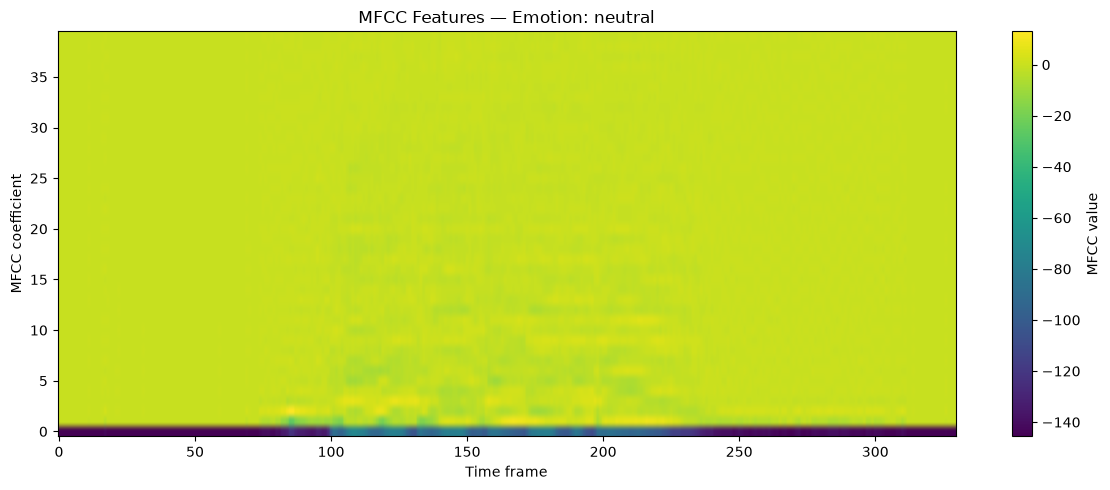

In [42]:

import numpy as np
import matplotlib.pyplot as plt

# Load the saved MFCC features and emotion labels
X = np.load("results/mfcc_features.npy")
emotion_labels = np.load(
    "results/emotion_labels.npy",
    allow_pickle=True
).astype(str)

# Select one sample for inspection
sample_index = 0
mfcc = X[sample_index]

print("Sample index:", sample_index)
print("Emotion:", emotion_labels[sample_index])
print("MFCC shape:", mfcc.shape)

# Plot the MFCC spectrogram
plt.figure(figsize=(12, 5))
plt.imshow(
    mfcc,
    aspect="auto",
    origin="lower",
    cmap="viridis"
)
plt.colorbar(label="MFCC value")
plt.xlabel("Time frame")
plt.ylabel("MFCC coefficient")
plt.title(
    f"MFCC Features — Emotion: {emotion_labels[sample_index]}"
)
plt.tight_layout()
plt.show()


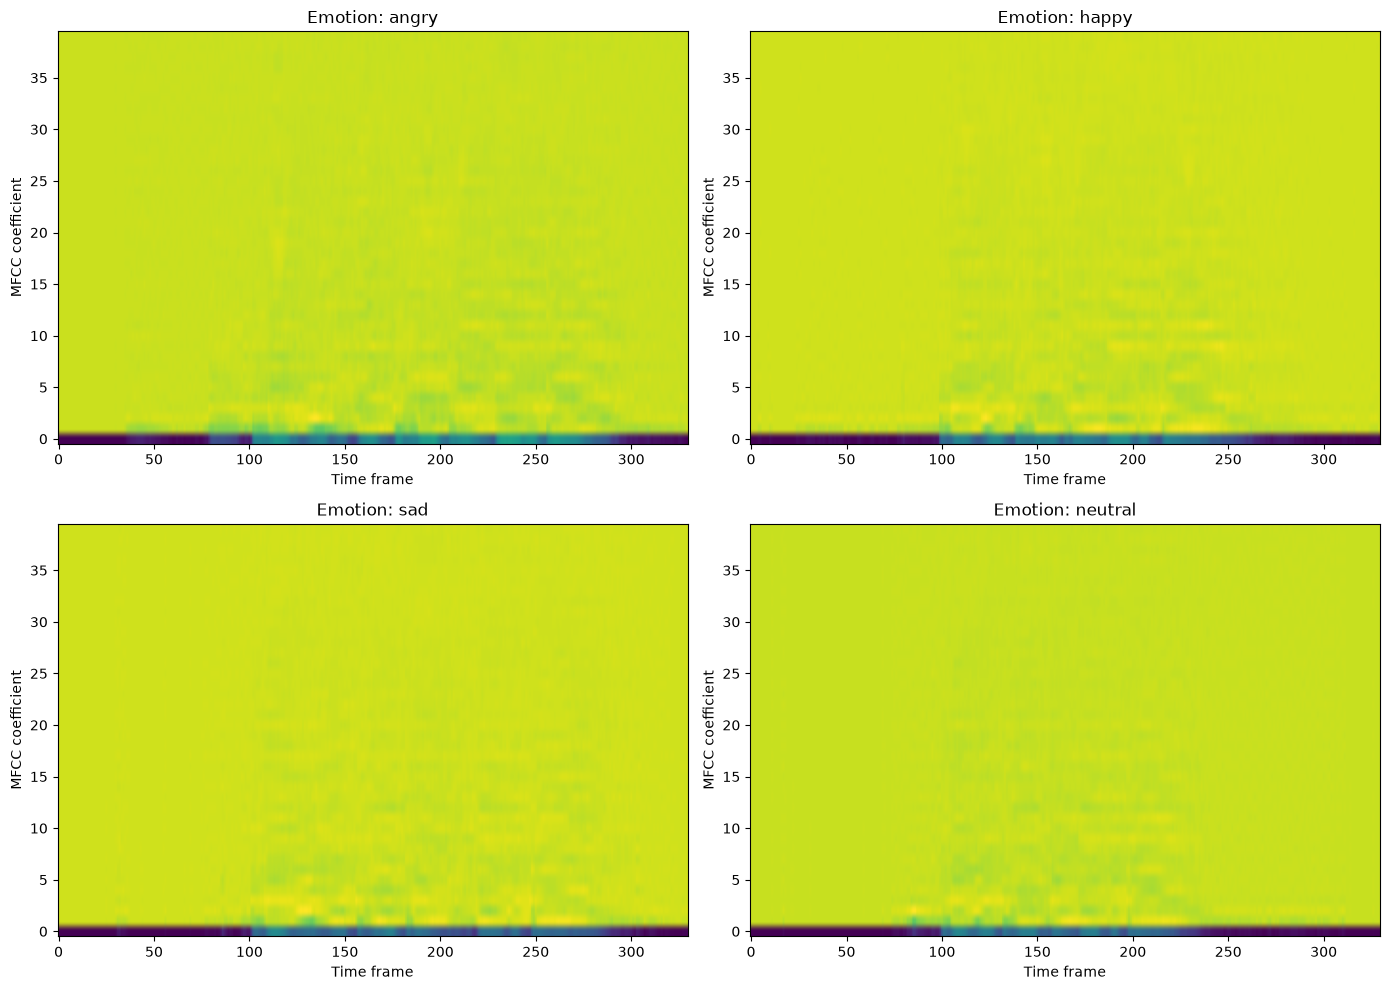

In [43]:
import numpy as np
import matplotlib.pyplot as plt

X = np.load("results/mfcc_features.npy")

emotion_labels = np.load(
    "results/emotion_labels.npy",
    allow_pickle=True
).astype(str)

emotions_to_show = ["angry", "happy", "sad", "neutral"]

plt.figure(figsize=(14, 10))

for i, emotion in enumerate(emotions_to_show):
    indices = np.where(emotion_labels == emotion)[0]

    sample_index = indices[0]
    mfcc = X[sample_index]

    plt.subplot(2, 2, i + 1)
    plt.imshow(
        mfcc,
        aspect="auto",
        origin="lower",
        cmap="viridis"
    )
    plt.title(f"Emotion: {emotion}")
    plt.xlabel("Time frame")
    plt.ylabel("MFCC coefficient")

plt.tight_layout()
plt.show()

In [44]:
import numpy as np

X = np.load("results/mfcc_features.npy")

sample_index = 0
mfcc = X[sample_index]

print("MFCC shape:", mfcc.shape)

# Check the first MFCC coefficient
first_coefficient = mfcc[0]

print("First coefficient minimum:", first_coefficient.min())
print("First coefficient maximum:", first_coefficient.max())
print("First coefficient standard deviation:", first_coefficient.std())

# Check how much the first coefficient changes over time
print("First 20 time-frame values:")
print(np.round(first_coefficient[:20], 2))

print("\nLast 20 time-frame values:")
print(np.round(first_coefficient[-20:], 2))

MFCC shape: (40, 330)
First coefficient minimum: -145.62827
First coefficient maximum: -72.54562
First coefficient standard deviation: 25.862707
First 20 time-frame values:
[-145.63 -145.63 -145.63 -145.63 -145.63 -145.63 -145.63 -145.63 -145.63
 -145.63 -145.63 -145.1  -145.63 -145.63 -145.63 -145.63 -145.39 -143.13
 -145.57 -145.63]

Last 20 time-frame values:
[-140.99 -143.05 -145.63 -145.63 -145.55 -145.62 -145.63 -145.63 -145.63
 -145.63 -145.63 -145.63 -145.63 -145.63 -145.63 -145.63 -144.92 -145.63
 -145.63 -145.63]


In [45]:
import numpy as np

X = np.load("results/mfcc_features.npy")

sample_index = 0
mfcc = X[sample_index]

# Check how much each time frame changes
frame_changes = np.mean(
    np.abs(np.diff(mfcc, axis=1)),
    axis=0
)

print("Total time frames:", mfcc.shape[1])
print("Average change between frames:", frame_changes.mean())
print("Minimum change:", frame_changes.min())

# Find frames with almost no change
unchanged_frames = np.sum(frame_changes < 0.01)

print("Nearly unchanged transitions:", unchanged_frames)

# Inspect the first MFCC coefficient
first_coefficient = mfcc[0]
floor_value = first_coefficient.min()

floor_frames = np.sum(
    np.isclose(first_coefficient, floor_value, atol=0.01)
)

print("Frames at the minimum value:", floor_frames)
print(
    "Percentage at minimum:",
    round(floor_frames / len(first_coefficient) * 100, 2),
    "%"
)

Total time frames: 330
Average change between frames: 0.34911984
Minimum change: 0.0
Nearly unchanged transitions: 69
Frames at the minimum value: 81
Percentage at minimum: 24.55 %


In [46]:
from pathlib import Path

project_path = Path.cwd()

print("Current folder:", project_path)
print("\nPython files in src:")

src_path = project_path / "src"

if src_path.exists():
    for file in src_path.glob("*.py"):
        print(file)
else:
    print("The src folder was not found in the current directory.")

Current folder: d:\ml projects\CodeAlpha_Emotion_Recognition_From_Speech

Python files in src:


In [47]:
from pathlib import Path

project_path = Path.cwd()

print("Jupyter notebooks found:\n")

for file in project_path.rglob("*.ipynb"):
    if "venv" not in file.parts and ".ipynb_checkpoints" not in file.parts:
        print(file.relative_to(project_path))

Jupyter notebooks found:

Emotion_Recognition_CNN.ipynb


In [49]:
from pathlib import Path

notebook_path = Path("Emotion_Recognition_CNN.ipynb")

print("File exists:", notebook_path.exists())

if notebook_path.exists():
    print("File size:", notebook_path.stat().st_size, "bytes")

    with open(notebook_path, "r", encoding="utf-8-sig") as file:
        print("\nFirst 300 characters:")
        print(repr(file.read(300)))

File exists: True
File size: 0 bytes

First 300 characters:
''


In [50]:
from pathlib import Path

project_path = Path.cwd()

print("Checking for notebook backups...\n")

for file in project_path.rglob("*"):
    if file.is_file():
        name = file.name.lower()

        if (
            file.suffix == ".ipynb"
            or ".ipynb_checkpoints" in str(file).lower()
        ):
            if "venv" not in file.parts:
                print(
                    f"{file.relative_to(project_path)} "
                    f"— {file.stat().st_size} bytes"
                )

Checking for notebook backups...

Emotion_Recognition_CNN.ipynb — 0 bytes


In [51]:
from pathlib import Path

project_path = Path.cwd()

for folder_name in ["results", "models", "data", "src"]:
    folder = project_path / folder_name
    print(f"\n--- {folder_name} ---")

    if folder.exists():
        for item in folder.iterdir():
            if item.is_file():
                print(f"{item.name} — {item.stat().st_size:,} bytes")
            elif item.is_dir():
                print(f"{item.name}/")
    else:
        print("Folder not found")


--- results ---
audio_dataset.csv — 194,159 bytes
classification_report.txt — 689 bytes
cnn_lstm_classification_report.txt — 726 bytes
cnn_lstm_confusion_matrix.png — 163,181 bytes
cnn_lstm_meanpool_test_predictions.csv — 6,193 bytes
cnn_lstm_meanpool_training_history.csv — 2,830 bytes
cnn_lstm_test_predictions.csv — 6,339 bytes
cnn_lstm_training_history.csv — 2,877 bytes
confusion_matrix.png — 171,062 bytes
emotion_classes.npy — 416 bytes
emotion_labels.npy — 51,968 bytes
improved_classification_report.txt — 689 bytes
improved_confusion_matrix.png — 166,259 bytes
mfcc_features.npy — 76,032,128 bytes
processed_audio_files.csv — 47,250 bytes
train_test_data.npz — 65,528,387 bytes
weighted_classification_report.txt — 720 bytes
weighted_confusion_matrix.png — 161,748 bytes
weighted_test_predictions.csv — 6,053 bytes

--- models ---
emotion_cnn.pth — 86,674 bytes
emotion_cnn_lstm.pth — 408,607 bytes
emotion_cnn_lstm_meanpool.pth — 409,086 bytes
emotion_cnn_weighted.pth — 87,127 bytes

---